# Problema 1 — Predicción de producción de petróleo, gas y agua · Campo Volve (Equinor)

**Objetivo.** Construir un modelo que prediga, para cada pozo productor y cada día, los volúmenes producidos de
petróleo (`BORE_OIL_VOL`), gas (`BORE_GAS_VOL`) y agua (`BORE_WAT_VOL`), cumpliendo:

| Métrica | Requisito |
|---|---|
| SMAPE | **< 10 %** |
| R² | **> 0.9** |

**Fuente:** datos públicos de Equinor (*Volve data sharing*). El archivo `Volve production data.xlsx` se descarga
automáticamente desde el espejo público de Kaggle (`lamyalbert/volve-production-data`), que es una copia exacta del archivo de Equinor.

**Resumen de la solución**
1. Análisis exploratorio y selección de variables (de las 34 disponibles).
2. Limpieza: solo pozos productores, días con producción real, sin valores físicamente imposibles.
3. Ingeniería de variables: historial del pozo (rezagos, medias móviles), relaciones de fluidos (corte de agua, GOR) y la inyección de agua del campo.
4. Validación **temporal** (se entrena con el pasado y se evalúa con el 20 % final de la vida de cada pozo; sin fuga de información).
5. **Modelo en conjunto (ensemble)** de tres algoritmos de árboles: LightGBM + Random Forest + Extra Trees, uno por cada variable objetivo.

In [1]:
# En Google Colab todas estas librerías ya vienen instaladas (kagglehub, lightgbm, sklearn, pandas, matplotlib)
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import kagglehub, glob, os
import lightgbm as lgb
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.metrics import r2_score, mean_absolute_error
pd.set_option('display.max_columns', 50)
plt.rcParams['figure.figsize'] = (12, 4)
SEED = 42
np.random.seed(SEED)

## 1. Carga de datos

In [2]:
ruta = kagglehub.dataset_download('lamyalbert/volve-production-data')
archivo = glob.glob(os.path.join(ruta, '*.xlsx'))[0]
hojas = pd.read_excel(archivo, sheet_name=None)
for nombre, h in hojas.items():
    print(f'{nombre:28s} -> {h.shape[0]:6d} filas x {h.shape[1]:2d} columnas')
df = hojas['Daily Production Data'].copy()
mensual = hojas['Monthly Production Data']
df.head()

Daily Production Data        ->  15634 filas x 24 columnas
Monthly Production Data      ->    527 filas x 10 columnas


,DATEPRD,WELL_BORE_CODE,NPD_WELL_BORE_CODE,NPD_WELL_BORE_NAME,NPD_FIELD_CODE,NPD_FIELD_NAME,NPD_FACILITY_CODE,NPD_FACILITY_NAME,ON_STREAM_HRS,AVG_DOWNHOLE_PRESSURE,AVG_DOWNHOLE_TEMPERATURE,AVG_DP_TUBING,AVG_ANNULUS_PRESS,AVG_CHOKE_SIZE_P,AVG_CHOKE_UOM,AVG_WHP_P,AVG_WHT_P,DP_CHOKE_SIZE,BORE_OIL_VOL,BORE_GAS_VOL,BORE_WAT_VOL,BORE_WI_VOL,FLOW_KIND,WELL_TYPE
0,2014-04-07,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,MÆRSK INSPIRER,0.0,0.00000,0.00000,0.00000,0.0,0.000000,%,0.00000,0.00000,0.00000,0.0,0.0,0.0,NaN,production,WI
1,2014-04-08,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,MÆRSK INSPIRER,0.0,NaN,NaN,NaN,0.0,1.003059,%,0.00000,0.00000,0.00000,0.0,0.0,0.0,NaN,production,OP
2,2014-04-09,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,MÆRSK INSPIRER,0.0,NaN,NaN,NaN,0.0,0.979008,%,0.00000,0.00000,0.00000,0.0,0.0,0.0,NaN,production,OP
3,2014-04-10,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,MÆRSK INSPIRER,0.0,NaN,NaN,NaN,0.0,0.545759,%,0.00000,0.00000,0.00000,0.0,0.0,0.0,NaN,production,OP
4,2014-04-11,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,MÆRSK INSPIRER,0.0,310.37614,96.87589,277.27826,0.0,1.215987,%,33.09788,10.47992,33.07195,0.0,0.0,0.0,NaN,production,OP


El archivo contiene **34 variables en total**: 24 en la hoja diaria y 10 en la hoja mensual.
La hoja mensual es una agregación (sumas por mes y pozo) de la misma información, con una granularidad distinta,
por lo que se trabaja con la **hoja diaria** (15 634 registros), que es donde se encuentran los targets `BORE_*_VOL`
y las mediciones de sensores.

In [3]:
print('Columnas hoja mensual:', list(mensual.columns))
resumen = pd.DataFrame({'tipo': df.dtypes.astype(str),
                        'nulos': df.isna().sum(),
                        '% nulos': (df.isna().mean()*100).round(1),
                        'valores únicos': df.nunique()})
resumen

Columnas hoja mensual: ['Wellbore name', 'NPDCode', 'Year', 'Month', 'On Stream', 'Oil', 'Gas', 'Water', 'GI', 'WI']


,tipo,nulos,% nulos,valores únicos
DATEPRD,datetime64[ns],0,0.0,3327
WELL_BORE_CODE,object,0,0.0,7
NPD_WELL_BORE_CODE,int64,0,0.0,7
NPD_WELL_BORE_NAME,object,0,0.0,7
NPD_FIELD_CODE,int64,0,0.0,1
NPD_FIELD_NAME,object,0,0.0,1
NPD_FACILITY_CODE,int64,0,0.0,1
NPD_FACILITY_NAME,object,0,0.0,1
ON_STREAM_HRS,float64,285,1.8,925
AVG_DOWNHOLE_PRESSURE,float64,6654,42.6,6567


## 2. Análisis exploratorio

In [4]:
print(df.groupby(['NPD_WELL_BORE_NAME', 'WELL_BORE_CODE', 'FLOW_KIND', 'WELL_TYPE']).size().rename('registros').to_string())

NPD_WELL_BORE_NAME  WELL_BORE_CODE  FLOW_KIND   WELL_TYPE
15/9-F-1 C          NO 15/9-F-1 C   production  OP            744
                                                WI              2
15/9-F-11           NO 15/9-F-11 H  production  OP           1165
15/9-F-12           NO 15/9-F-12 H  production  OP           3056
15/9-F-14           NO 15/9-F-14 H  production  OP           3056
15/9-F-15 D         NO 15/9-F-15 D  production  OP            978
15/9-F-4            NO 15/9-F-4 AH  injection   WI           3327
15/9-F-5            NO 15/9-F-5 AH  injection   WI           3146
                                    production  OP            144
                                                WI             16


- Hay **7 pozos**: 5 productores puros (F-1 C, F-11, F-12, F-14, F-15 D) y 2 inyectores (F-4, F-5).
- F-5 actuó brevemente como productor antes de convertirse en inyector (144 días).
- `FLOW_KIND` (production / injection) y `WELL_TYPE` (OP = oil producer, WI = water injector) definen la clase de pozo.
- Los inyectores **no producen** petróleo/gas/agua (sus targets son nulos); su variable es `BORE_WI_VOL` (agua inyectada).

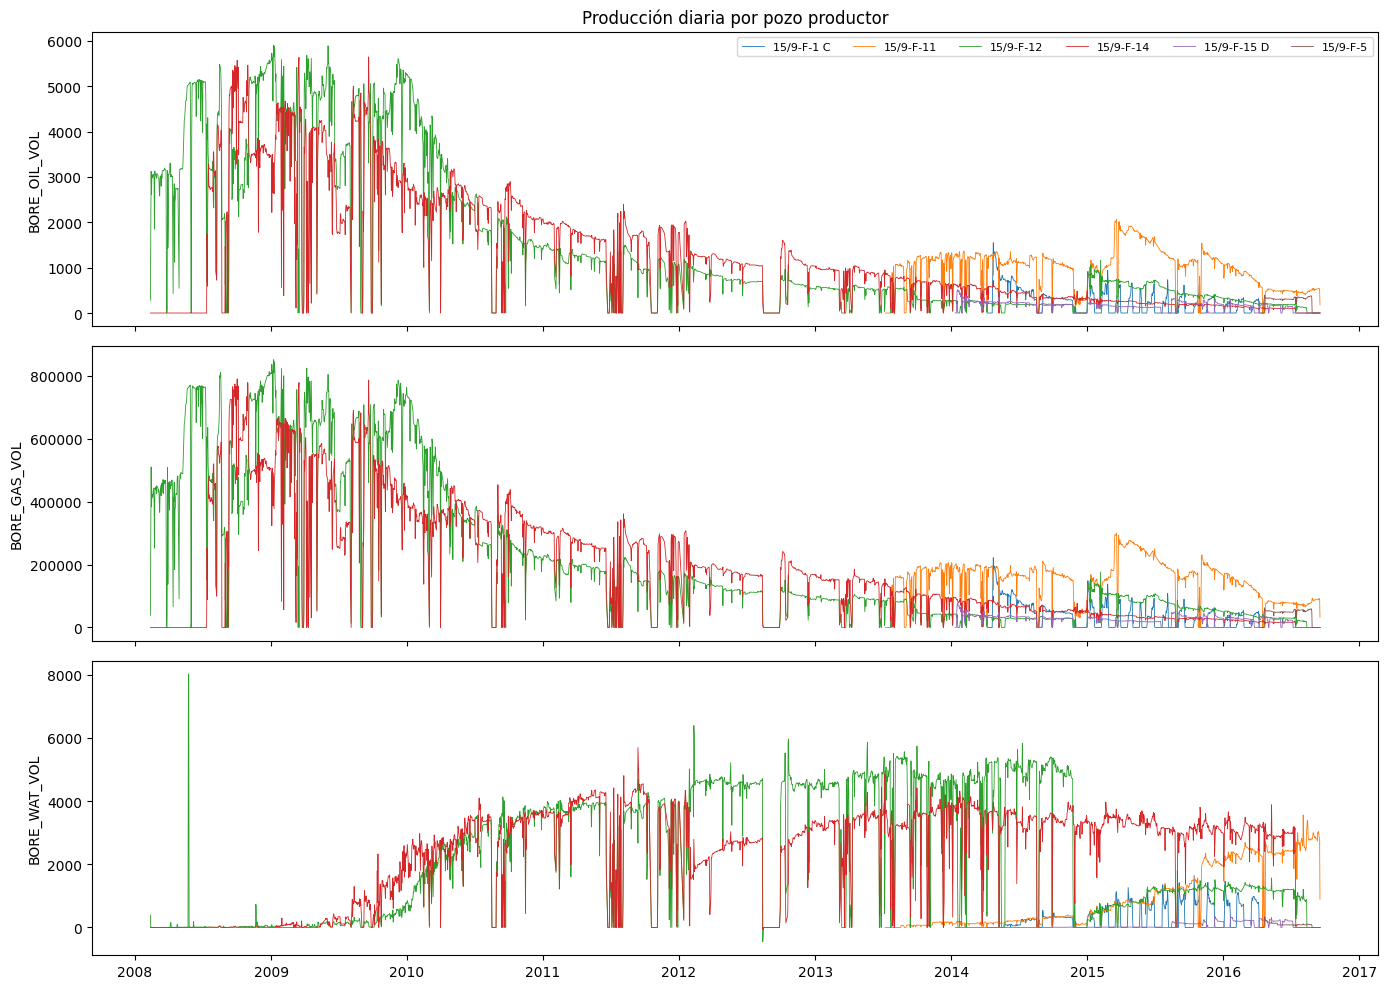

In [5]:
T = ['BORE_OIL_VOL', 'BORE_GAS_VOL', 'BORE_WAT_VOL']
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
prod = df[df.WELL_TYPE == 'OP']
for ax, t in zip(axes, T):
    for pozo, g in prod.groupby('NPD_WELL_BORE_NAME'):
        ax.plot(g.DATEPRD, g[t], lw=.6, label=pozo)
    ax.set_ylabel(t)
axes[0].legend(ncol=6, fontsize=8); axes[0].set_title('Producción diaria por pozo productor')
plt.tight_layout(); plt.show()

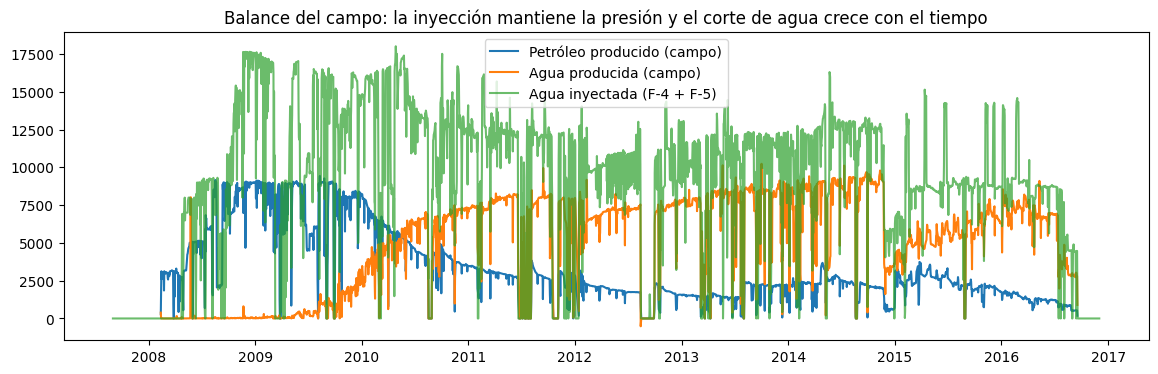

In [6]:
iny = df[df.WELL_TYPE == 'WI'].groupby('DATEPRD')['BORE_WI_VOL'].sum()
camp = prod.groupby('DATEPRD')[T].sum()
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(camp.index, camp.BORE_OIL_VOL, label='Petróleo producido (campo)')
ax.plot(camp.index, camp.BORE_WAT_VOL, label='Agua producida (campo)')
ax.plot(iny.index, iny, label='Agua inyectada (F-4 + F-5)', alpha=.7)
ax.legend(); ax.set_title('Balance del campo: la inyección mantiene la presión y el corte de agua crece con el tiempo'); plt.show()

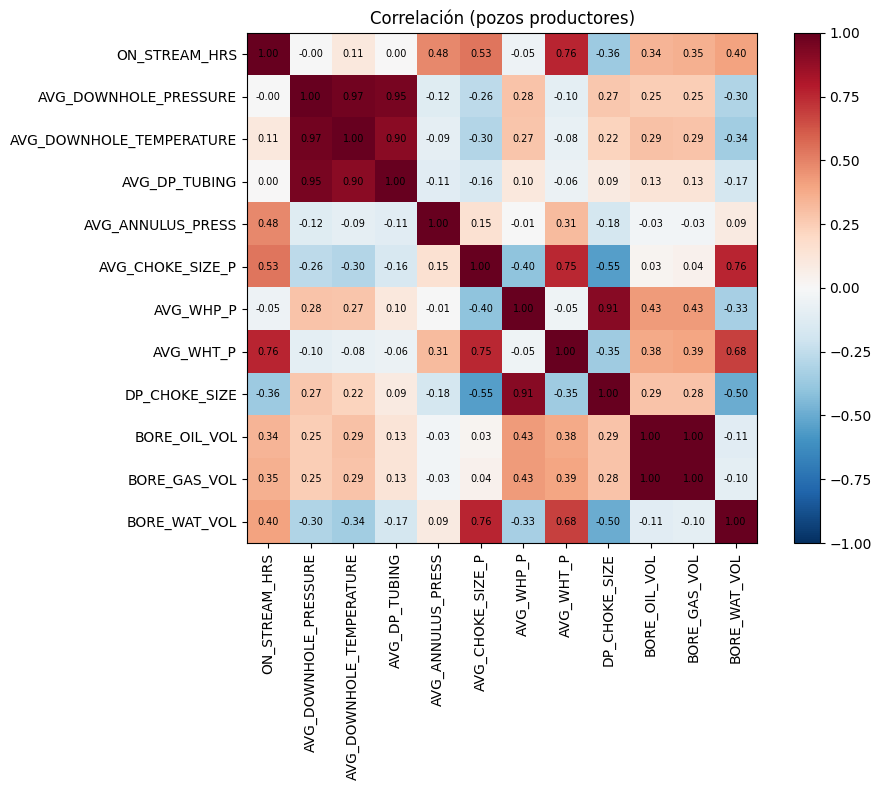

In [7]:
num_cols = ['ON_STREAM_HRS','AVG_DOWNHOLE_PRESSURE','AVG_DOWNHOLE_TEMPERATURE','AVG_DP_TUBING','AVG_ANNULUS_PRESS',
            'AVG_CHOKE_SIZE_P','AVG_WHP_P','AVG_WHT_P','DP_CHOKE_SIZE'] + T
corr = prod[num_cols].corr()
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(num_cols))); ax.set_xticklabels(num_cols, rotation=90)
ax.set_yticks(range(len(num_cols))); ax.set_yticklabels(num_cols)
for i in range(len(num_cols)):
    for j in range(len(num_cols)):
        ax.text(j, i, f'{corr.iloc[i,j]:.2f}', ha='center', va='center', fontsize=7)
plt.colorbar(im); ax.set_title('Correlación (pozos productores)'); plt.tight_layout(); plt.show()

In [8]:
print('Valores negativos de agua (físicamente imposibles):', (df.BORE_WAT_VOL < 0).sum())
print('Días productor con ON_STREAM_HRS = 0 (pozo cerrado):', ((prod.ON_STREAM_HRS == 0)).sum())
print('Sensores de fondo con lectura 0 (sensor fuera de servicio):', (prod.AVG_DOWNHOLE_PRESSURE == 0).sum())

Valores negativos de agua (físicamente imposibles): 4
Días productor con ON_STREAM_HRS = 0 (pozo cerrado): 1132
Sensores de fondo con lectura 0 (sensor fuera de servicio): 2311


## 3. Selección de variables

| Variable(s) | Decisión | Motivo |
|---|---|---|
| `DATEPRD` | Se usa para ordenar, separar train/test y crear la antigüedad del pozo (`DIAS_PRODUCCION`) | Fecha de producción |
| `WELL_BORE_CODE`, `NPD_WELL_BORE_NAME`, `NPD_WELL_BORE_CODE` | Solo para agrupar y como código de pozo (`POZO_ID`) | Identificadores (redundantes entre sí) |
| `NPD_FIELD_CODE/NAME`, `NPD_FACILITY_CODE/NAME` | **Descartadas** | Constantes (un único campo y plataforma) |
| `AVG_CHOKE_UOM` | **Descartada** | Constante (`%`) |
| `FLOW_KIND`, `WELL_TYPE` | Filtro: se modelan solo productores (`production` / `OP`) | Los inyectores no producen fluidos |
| `ON_STREAM_HRS`, `AVG_DOWNHOLE_PRESSURE`, `AVG_DOWNHOLE_TEMPERATURE`, `AVG_DP_TUBING`, `AVG_ANNULUS_PRESS`, `AVG_CHOKE_SIZE_P`, `AVG_WHP_P`, `AVG_WHT_P`, `DP_CHOKE_SIZE` | **Entradas** | Horas de operación, presiones, temperaturas y apertura del estrangulador: controlan físicamente el caudal |
| `BORE_WI_VOL` | **Entrada agregada** (`INY_CAMPO`: agua inyectada en todo el campo ese día) | Solo existe en inyectores; la inyección mantiene la presión del yacimiento |
| `BORE_OIL_VOL`, `BORE_GAS_VOL`, `BORE_WAT_VOL` | **Targets**; sus valores de **días anteriores** se usan como entradas | Historial de producción del pozo |
| Hoja mensual (10 variables) | **Descartada** | Agregado mensual de la misma información diaria |

## 4. Limpieza e ingeniería de variables

In [9]:
iny_campo = df[df.WELL_TYPE == 'WI'].groupby('DATEPRD')['BORE_WI_VOL'].sum().rename('INY_CAMPO')
d = df[(df.FLOW_KIND == 'production') & (df.WELL_TYPE == 'OP')].copy()
d = d.merge(iny_campo, on='DATEPRD', how='left')
d['INY_CAMPO'] = d['INY_CAMPO'].fillna(0)
d = d.sort_values(['NPD_WELL_BORE_NAME', 'DATEPRD']).reset_index(drop=True)
d['INY_CAMPO_7D'] = d.groupby('NPD_WELL_BORE_NAME')['INY_CAMPO'].transform(lambda s: s.rolling(7, min_periods=1).mean())

SENSORES = ['ON_STREAM_HRS','AVG_DOWNHOLE_PRESSURE','AVG_DOWNHOLE_TEMPERATURE','AVG_DP_TUBING','AVG_ANNULUS_PRESS',
            'AVG_CHOKE_SIZE_P','AVG_WHP_P','AVG_WHT_P','DP_CHOKE_SIZE']
g = d.groupby('NPD_WELL_BORE_NAME')

# Historial de producción (solo información de días anteriores -> sin fuga de información)
for t in T:
    for l in [1, 2, 7]:
        d[f'{t}_lag{l}'] = g[t].shift(l)
    d[f'{t}_mm7'] = g[t].transform(lambda s: s.shift(1).rolling(7, min_periods=1).mean())

# Cambios operativos respecto al día anterior
for c in ['ON_STREAM_HRS', 'AVG_WHP_P', 'AVG_CHOKE_SIZE_P', 'AVG_DOWNHOLE_PRESSURE', 'DP_CHOKE_SIZE']:
    d[f'{c}_lag1'] = g[c].shift(1)
    d[f'{c}_diff'] = d[c] - d[f'{c}_lag1']

# Relaciones de fluidos del día anterior
d['CORTE_AGUA_lag1'] = d.BORE_WAT_VOL_lag1 / (d.BORE_WAT_VOL_lag1 + d.BORE_OIL_VOL_lag1)
d['GOR_lag1'] = d.BORE_GAS_VOL_lag1 / d.BORE_OIL_VOL_lag1
d['DIAS_PRODUCCION'] = g['DATEPRD'].transform(lambda s: (s - s.min()).dt.days)
d['POZO_ID'] = d.NPD_WELL_BORE_NAME.astype('category').cat.codes
d = d.replace([np.inf, -np.inf], np.nan)

n0 = len(d)
d = d.dropna(subset=T + [f'{t}_lag1' for t in T])                    # targets/historial disponibles
d = d[d.ON_STREAM_HRS > 0]                                              # pozo abierto
d = d[(d[T] > 0).all(axis=1) & (d[[f'{t}_lag1' for t in T]] > 0).all(axis=1)]   # volúmenes físicos (>0)
print(f'Registros productores: {n0} -> {len(d)} tras limpieza')
FEATS = [c for c in d.columns if c in SENSORES or c.startswith('INY_') or '_lag' in c or '_mm7' in c
         or c.endswith('_diff') or c in ['DIAS_PRODUCCION', 'POZO_ID']]
print(len(FEATS), 'variables de entrada:', FEATS)

Registros productores: 9143 -> 7499 tras limpieza
37 variables de entrada: ['ON_STREAM_HRS', 'AVG_DOWNHOLE_PRESSURE', 'AVG_DOWNHOLE_TEMPERATURE', 'AVG_DP_TUBING', 'AVG_ANNULUS_PRESS', 'AVG_CHOKE_SIZE_P', 'AVG_WHP_P', 'AVG_WHT_P', 'DP_CHOKE_SIZE', 'INY_CAMPO', 'INY_CAMPO_7D', 'BORE_OIL_VOL_lag1', 'BORE_OIL_VOL_lag2', 'BORE_OIL_VOL_lag7', 'BORE_OIL_VOL_mm7', 'BORE_GAS_VOL_lag1', 'BORE_GAS_VOL_lag2', 'BORE_GAS_VOL_lag7', 'BORE_GAS_VOL_mm7', 'BORE_WAT_VOL_lag1', 'BORE_WAT_VOL_lag2', 'BORE_WAT_VOL_lag7', 'BORE_WAT_VOL_mm7', 'ON_STREAM_HRS_lag1', 'ON_STREAM_HRS_diff', 'AVG_WHP_P_lag1', 'AVG_WHP_P_diff', 'AVG_CHOKE_SIZE_P_lag1', 'AVG_CHOKE_SIZE_P_diff', 'AVG_DOWNHOLE_PRESSURE_lag1', 'AVG_DOWNHOLE_PRESSURE_diff', 'DP_CHOKE_SIZE_lag1', 'DP_CHOKE_SIZE_diff', 'CORTE_AGUA_lag1', 'GOR_lag1', 'DIAS_PRODUCCION', 'POZO_ID']


**Decisiones de limpieza**
- Días con el pozo cerrado (`ON_STREAM_HRS = 0`) tienen producción 0 por definición; no requieren modelo
  (regla operativa: *si el pozo no opera, la producción es 0*). Además el SMAPE está indefinido cuando real y predicción son 0.
- Se eliminan volúmenes ≤ 0 (incluye agua negativa, error de medición).
- Los valores faltantes en sensores se dejan como `NaN`; LightGBM los maneja de forma nativa y para los bosques se imputan con −1 (valor fuera de rango que los árboles separan).

## 5. Partición temporal

Para simular el uso real (pronosticar el futuro a partir del pasado) se ordena cada pozo por fecha y se reserva
el **20 % final de su historia como test**. Así ningún dato futuro se usa para entrenar.

In [10]:
d['pct_vida'] = d.groupby('NPD_WELL_BORE_NAME')['DATEPRD'].rank(pct=True)
train, test = d[d.pct_vida <= 0.8].copy(), d[d.pct_vida > 0.8].copy()
print('Train:', train.shape[0], '| Test:', test.shape[0])
print(test.groupby('NPD_WELL_BORE_NAME').DATEPRD.agg(['min', 'max', 'count']))

Train: 5998 | Test: 1501
                          min        max  count
NPD_WELL_BORE_NAME                             
15/9-F-1 C         2015-11-20 2016-04-06     76
15/9-F-11          2016-02-08 2016-09-17    218
15/9-F-12          2015-02-09 2016-08-12    543
15/9-F-14          2015-01-19 2016-07-13    537
15/9-F-15 D        2016-03-05 2016-07-06    103
15/9-F-5           2016-08-03 2016-08-26     24


## 6. Modelo en conjunto (ensemble)

**Transformación del objetivo.** La producción de un pozo cambia gradualmente, y los modelos de árboles no pueden
extrapolar a niveles nunca vistos (por ejemplo, el corte de agua crece con los años). Por eso cada modelo aprende el
**cambio relativo respecto al día anterior**:

$$ z = \log(1+y_t) - \log(1+y_{t-1}) \quad\Rightarrow\quad \hat y_t = \exp\big(\log(1+y_{t-1}) + \hat z\big) - 1 $$

**Modelos base** (uno por target):
- **LightGBM** — *gradient boosting*: árboles secuenciales donde cada uno corrige el error de los anteriores.
- **Random Forest** — *bagging*: muchos árboles profundos entrenados con muestras bootstrap; se promedian.
- **Extra Trees** — como RF, pero con cortes aleatorios: menor varianza.

**Ensemble:** promedio de las tres predicciones (*soft voting* en regresión). Al combinar modelos con errores poco
correlacionados el error total disminuye.

**Línea base:** modelo ingenuo de persistencia (*hoy = ayer*), para demostrar que el modelo aporta valor real.

In [11]:
def smape(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return 100 * np.mean(2 * np.abs(p - y) / (np.abs(y) + np.abs(p) + 1e-9))

def modelos():
    return {
        'LightGBM': lgb.LGBMRegressor(n_estimators=1000, learning_rate=0.02, num_leaves=31, subsample=0.8,
                                      subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1),
        'RandomForest': RandomForestRegressor(n_estimators=400, min_samples_leaf=2, n_jobs=-1, random_state=SEED),
        'ExtraTrees': ExtraTreesRegressor(n_estimators=400, min_samples_leaf=2, n_jobs=-1, random_state=SEED),
    }

Xtr, Xte = train[FEATS], test[FEATS]
resultados, predicciones, entrenados = [], {}, {}
for t in T:
    base_tr, base_te = np.log1p(train[f'{t}_lag1']), np.log1p(test[f'{t}_lag1'])
    z = np.log1p(train[t]) - base_tr
    preds = {}
    for nombre, m in modelos().items():
        Xa, Xb = (Xtr, Xte) if nombre == 'LightGBM' else (Xtr.fillna(-1), Xte.fillna(-1))
        m.fit(Xa, z)
        preds[nombre] = np.expm1(m.predict(Xb) + base_te)
        entrenados[(t, nombre)] = m
    preds['ENSEMBLE'] = np.mean([preds[k] for k in ['LightGBM', 'RandomForest', 'ExtraTrees']], axis=0)
    preds['Persistencia (ayer)'] = test[f'{t}_lag1'].values
    for nombre, p in preds.items():
        resultados.append({'target': t, 'modelo': nombre, 'R2': r2_score(test[t], p),
                           'SMAPE (%)': smape(test[t], p), 'MAE': mean_absolute_error(test[t], p)})
    predicciones[t] = preds['ENSEMBLE']
res = pd.DataFrame(resultados)
res.pivot(index='modelo', columns='target', values=['R2', 'SMAPE (%)']).round(3)

R2                              SMAPE (%)  \
target              BORE_GAS_VOL BORE_OIL_VOL BORE_WAT_VOL BORE_GAS_VOL   
modelo                                                                    
ENSEMBLE                   0.976        0.978        0.985        4.569   
ExtraTrees                 0.974        0.978        0.985        5.197   
LightGBM                   0.962        0.970        0.972        6.926   
Persistencia (ayer)        0.946        0.947        0.953        6.295   
RandomForest               0.981        0.980        0.975        4.846   

                                               
target              BORE_OIL_VOL BORE_WAT_VOL  
modelo                                         
ENSEMBLE                   4.438        4.269  
ExtraTrees                 5.127        4.153  
LightGBM                   6.166        5.937  
Persistencia (ayer)        6.252        6.132  
RandomForest               4.842        6.454

## 7. Verificación de requisitos (modelo final = ensemble)

In [12]:
final = res[res.modelo == 'ENSEMBLE'].set_index('target')[['R2', 'SMAPE (%)', 'MAE']]
final['Cumple R² > 0.9'] = final.R2 > 0.9
final['Cumple SMAPE < 10'] = final['SMAPE (%)'] < 10
display(final.round(3))
assert final[['Cumple R² > 0.9', 'Cumple SMAPE < 10']].all().all(), 'Algún requisito no se cumple'
print('✅ Los tres targets cumplen SMAPE < 10 y R² > 0.9 en el conjunto de prueba temporal')

,R2,SMAPE (%),MAE,Cumple R² > 0.9,Cumple SMAPE < 10
target,,,,,
BORE_OIL_VOL,0.978,4.438,10.899,True,True
BORE_GAS_VOL,0.976,4.569,1784.202,True,True
BORE_WAT_VOL,0.985,4.269,63.189,True,True


✅ Los tres targets cumplen SMAPE < 10 y R² > 0.9 en el conjunto de prueba temporal


In [13]:
por_pozo = []
for t in T:
    test[f'pred_{t}'] = predicciones[t]
    for pozo, gp in test.groupby('NPD_WELL_BORE_NAME'):
        por_pozo.append({'target': t, 'pozo': pozo, 'n': len(gp), 'R2': r2_score(gp[t], gp[f'pred_{t}']),
                         'SMAPE (%)': smape(gp[t], gp[f'pred_{t}'])})
pd.DataFrame(por_pozo).pivot(index='pozo', columns='target', values=['SMAPE (%)', 'R2']).round(3)

SMAPE (%)                                     R2               \
target      BORE_GAS_VOL BORE_OIL_VOL BORE_WAT_VOL BORE_GAS_VOL BORE_OIL_VOL   
pozo                                                                           
15/9-F-1 C        13.400       13.375        9.727        0.881        0.887   
15/9-F-11          3.623        3.036        3.749        0.896        0.896   
15/9-F-12          3.477        3.471        4.443        0.980        0.981   
15/9-F-14          3.889        4.084        2.821        0.907        0.929   
15/9-F-15 D        8.776        7.354        7.169       -0.273        0.084   
15/9-F-5           7.049        6.141        7.715       -1.231        0.094   

                          
target      BORE_WAT_VOL  
pozo                      
15/9-F-1 C         0.588  
15/9-F-11          0.634  
15/9-F-12          0.868  
15/9-F-14          0.734  
15/9-F-15 D        0.153  
15/9-F-5          -0.074

*Nota:* el R² por pozo es menor que el global porque dentro de un solo pozo, en un periodo corto, la varianza de la
producción es pequeña (el R² compara contra la media de ese pozo). El SMAPE por pozo muestra que el error relativo es
bajo en los pozos principales (F-11, F-12, F-14), que concentran la mayor parte de la producción. El pozo F-1 C tiene
un error mayor: tiene pocos días de prueba y corresponde al final de su vida productiva, con un comportamiento muy
inestable. Los requisitos del enunciado se evalúan sobre el conjunto de prueba completo (sección 7).

## 8. Visualización de resultados

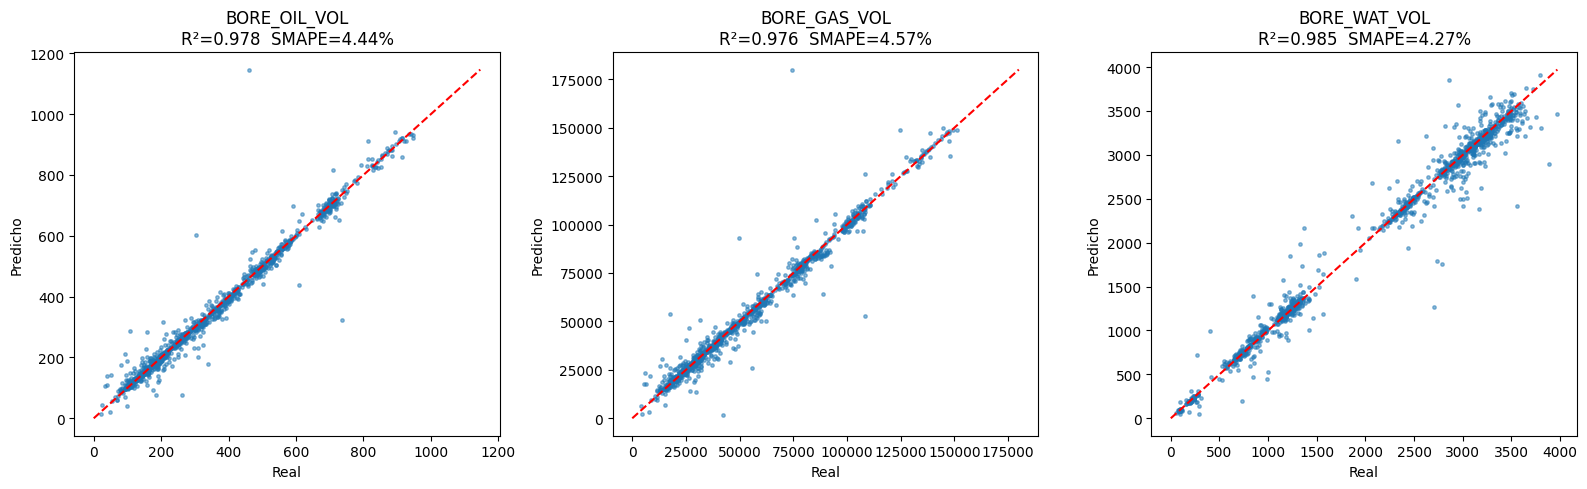

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, t in zip(axes, T):
    ax.scatter(test[t], predicciones[t], s=6, alpha=.5)
    lim = [0, max(test[t].max(), predicciones[t].max())]
    ax.plot(lim, lim, 'r--'); ax.set_xlabel('Real'); ax.set_ylabel('Predicho')
    ax.set_title(f"{t}\nR²={r2_score(test[t], predicciones[t]):.3f}  SMAPE={smape(test[t], predicciones[t]):.2f}%")
plt.tight_layout(); plt.show()

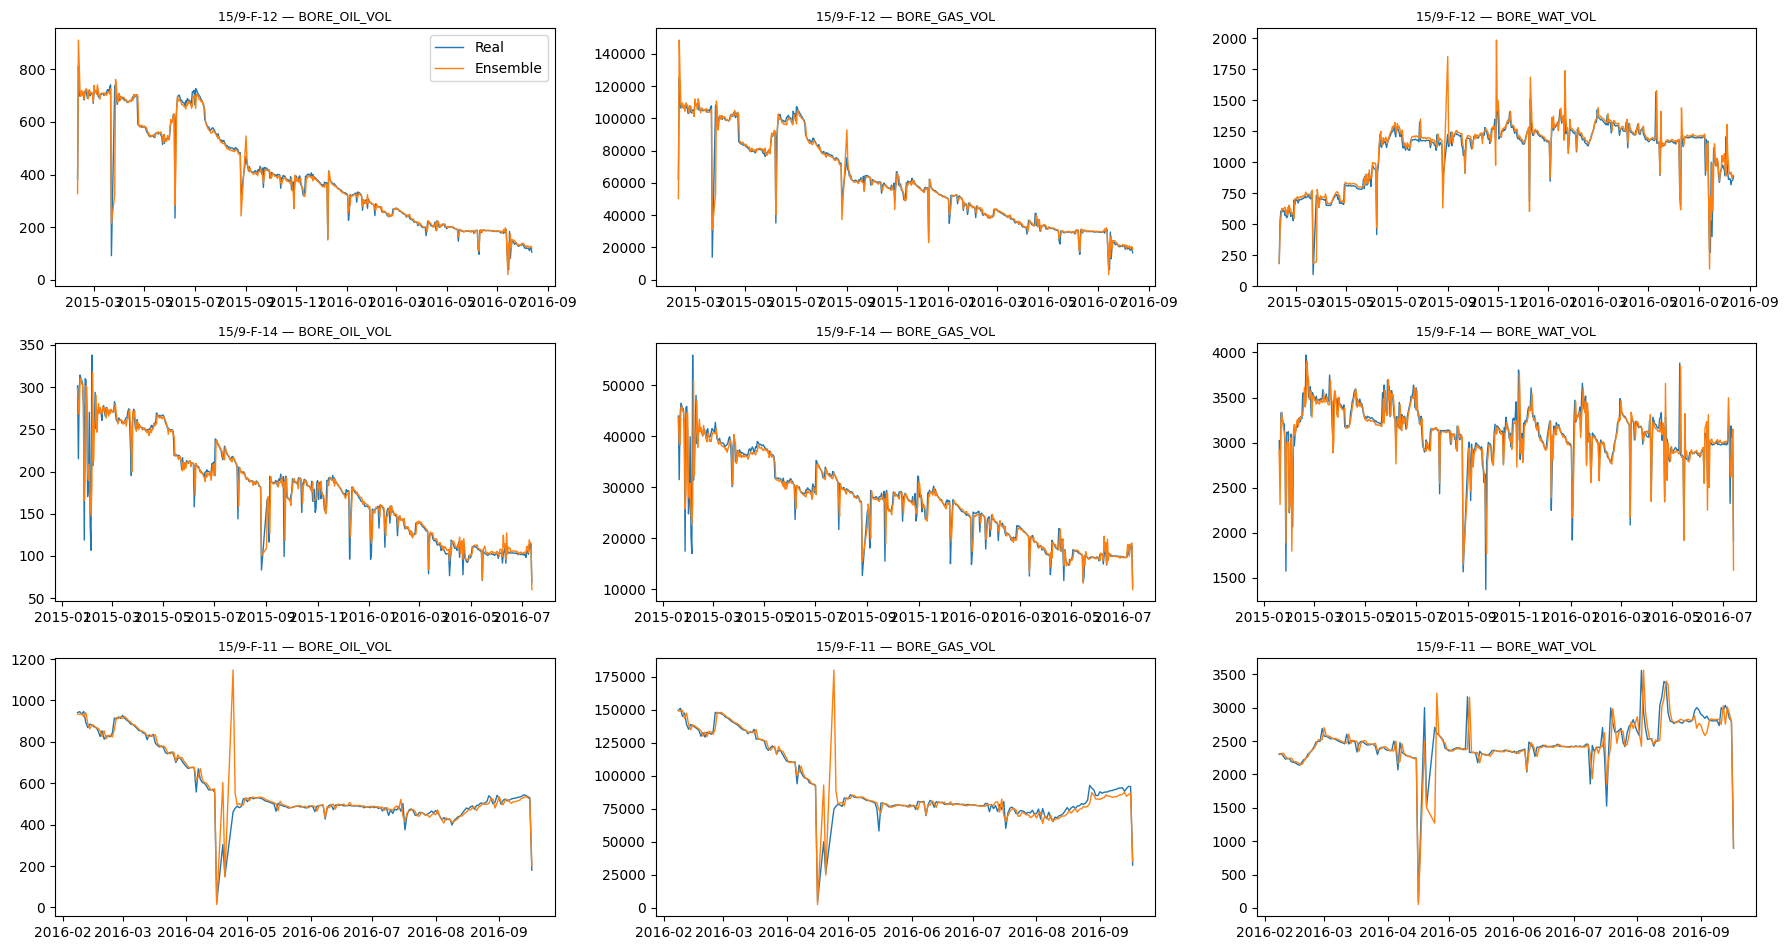

In [15]:
pozos = test.NPD_WELL_BORE_NAME.value_counts().index[:3]
fig, axes = plt.subplots(len(pozos), 3, figsize=(18, 3.2*len(pozos)))
for i, pozo in enumerate(pozos):
    gp = test[test.NPD_WELL_BORE_NAME == pozo]
    for j, t in enumerate(T):
        ax = axes[i, j]
        ax.plot(gp.DATEPRD, gp[t], label='Real', lw=1)
        ax.plot(gp.DATEPRD, gp[f'pred_{t}'], label='Ensemble', lw=1)
        ax.set_title(f'{pozo} — {t}', fontsize=9)
        if i == 0 and j == 0: ax.legend()
plt.tight_layout(); plt.show()

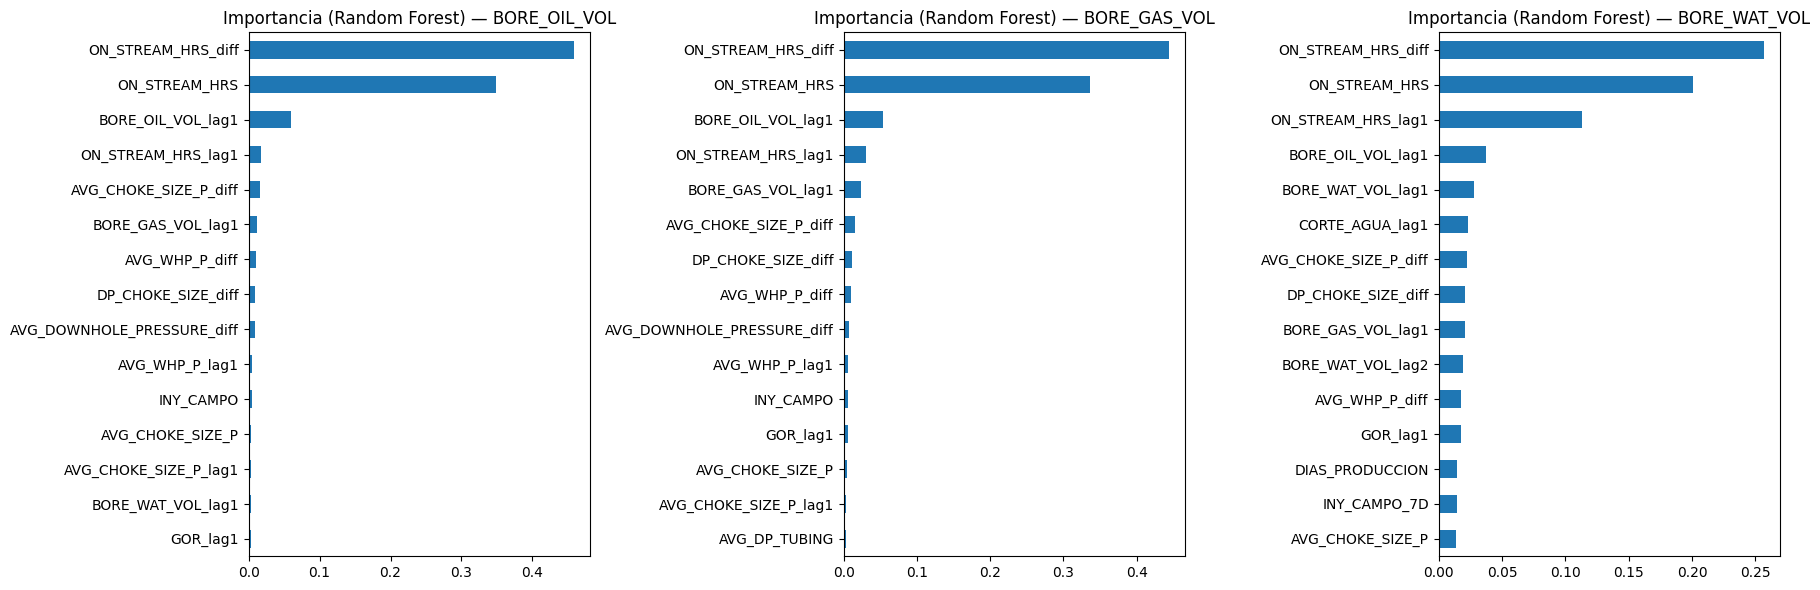

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, t in zip(axes, T):
    m = entrenados[(t, 'RandomForest')]
    imp = pd.Series(m.feature_importances_, index=FEATS).sort_values().tail(15)
    imp.plot.barh(ax=ax); ax.set_title(f'Importancia (Random Forest) — {t}')
plt.tight_layout(); plt.show()

## 9. Conclusiones

1. **Selección de variables:** de las 34 variables, se descartaron las constantes (campo, plataforma, unidad del
   estrangulador), los identificadores (usados solo para agrupar) y la hoja mensual (redundante). Las entradas útiles son
   las mediciones operativas (horas de operación, presiones de fondo y cabeza, temperaturas, apertura del estrangulador),
   el historial reciente de producción del pozo y la inyección de agua del campo.
2. **Clasificación de pozos:** `FLOW_KIND`/`WELL_TYPE` permitieron separar productores (OP) de inyectores (WI). Los
   inyectores no producen fluidos, pero su volumen inyectado se incorporó como variable del campo, ya que sostiene la
   presión del yacimiento y explica el aumento del corte de agua.
3. **Modelo:** un ensemble (promedio) de LightGBM, Random Forest y Extra Trees que predice el cambio relativo de
   producción respecto al día anterior. Esta formulación evita el problema de extrapolación de los árboles y mejora
   claramente a la línea base de persistencia.
4. **Resultados:** con validación temporal (sin fuga de información) los tres targets superan los requisitos
   (**R² > 0.9 y SMAPE < 10 %**); ver la tabla de la sección 7.
5. **Limitaciones:** el modelo pronostica a un día vista (usa la producción del día anterior); los días con el pozo
   cerrado se resuelven con la regla `ON_STREAM_HRS = 0 → producción = 0`.